## 1. Tugas Pendahuluan

### 1.1 Persiapan dan Perkenalan Lingkungan

Environment dibuat menggunakan Python 3.10.11 dan `venv` melalui terminal VS Code. Environment diberi nama `myenv` agar library yang digunakan tidak bercampur dengan proyek lain.

Perintah yang digunakan:

```powershell
python -m venv myenv
.\myenv\Scripts\Activate.ps1
```

Setelah environment aktif, dilakukan instalasi library yang diperlukan untuk pengolahan data RetailRocket, koneksi Neo4j, VSM, dan visualisasi graf.

```powershell
python -m pip install neo4j pandas tqdm numpy scipy scikit-learn networkx matplotlib ipykernel
```

Kernel Jupyter Notebook kemudian diatur menggunakan `myenv (Python 3.10.11)`.

### 1.2 Mempelajari Penggunaan Driver Neo4j

In [46]:
from neo4j import GraphDatabase
from getpass import getpass

URI = "bolt://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = getpass("Masukkan password Neo4j: ")

driver = GraphDatabase.driver(
    URI,
    auth=(USER, PASSWORD)
)

try:
    driver.verify_connectivity()
    print("Koneksi Python ke Neo4j berhasil!")
except Exception as e:
    print("Koneksi gagal:", e)

Koneksi Python ke Neo4j berhasil!


#### 1.2.1 Membuat Node dan Relationship Pertemanan

In [47]:
def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            """
            MERGE (a:Person {name: $name})
            MERGE (friend:Person {name: $friend_name})
            MERGE (a)-[:KNOWS]->(friend)
            """,
            name=name,
            friend_name=friend_name
        )

# Membuat graf pertemanan
add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")

print("Graf pertemanan berhasil dibuat!")

Graf pertemanan berhasil dibuat!


#### 1.2.2 Menampilkan Daftar Teman Arthur

In [48]:
def print_friends(driver, name):
    with driver.session(database="neo4j") as session:
        result = session.run(
            """
            MATCH (a:Person)-[:KNOWS]->(friend)
            WHERE a.name = $name
            RETURN friend.name AS teman
            ORDER BY teman
            """,
            name=name
        )

        for record in result:
            print(record["teman"])

print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


### 1.2.3 Pertanyaan Pendahuluan (Checkpoint)

**1. Apa nama database yang digunakan pada tutorial ini?**

Database yang digunakan adalah `neo4j`, sesuai dengan parameter `database="neo4j"` pada saat membuat session.

**2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan untuk mengakses database lain dalam satu instance!**

Untuk mengakses database lain dalam satu instance Neo4j, dapat menggunakan perintah Cypher `SHOW DATABASES` untuk melihat daftar database dan `:use retailrocket` untuk berpindah database melalui Neo4j Browser. Melalui Python Driver, database juga dapat ditentukan menggunakan `driver.session(database="retailrocket")`.

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**

Graf yang dibuat merupakan *directed graph* atau graf berarah, karena relationship `KNOWS` memiliki arah dari Arthur menuju Guinevere, Lancelot, dan Merlin. Node menggunakan label `Person`, sedangkan relationship menggunakan tipe `KNOWS`.

### 1.3 Melakukan Proses Impor Data dari RetailRocket ke Database Neo4j

In [75]:
import pandas as pd

# Membaca dataset RetailRocket
df = pd.read_csv("events.csv")

# Melihat ukuran dan contoh data
print("Jumlah baris dan kolom:", df.shape)
display(df.head())

Jumlah baris dan kolom: (2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


#### 1.3.1 Memeriksa Hasil Impor Data ke Neo4j

In [50]:
with driver.session(database="retailrocket") as session:
    result = session.run("""
        MATCH (n)
        RETURN labels(n)[0] AS label, count(n) AS jumlah
        ORDER BY label
    """)

    for record in result:
        print(record["label"], ":", record["jumlah"])

Item : 117317
Visitor : 313832


#### 1.3.2 Memeriksa Jumlah Relationship

In [51]:
with driver.session(database="retailrocket") as session:
    result = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS relationship, count(r) AS jumlah
        ORDER BY relationship
    """)

    for record in result:
        print(record["relationship"], ":", record["jumlah"])

ADDED_TO_CART : 15095
BOUGHT : 5043
SIMILAR_TO : 5
VIEWED : 590255


### 1.3.3 Hasil Pemeriksaan Data

Data RetailRocket periode P1 (1–14 Juli 2015) sudah tersimpan dalam database `retailrocket` di Neo4j. Hasil pemeriksaan menunjukkan terdapat **171.802 node Visitor** dan **83.507 node Item**.

Relationship yang terbentuk terdiri dari **299.629 VIEWED**, **7.535 ADDED_TO_CART**, dan **2.473 BOUGHT**. Totalnya adalah **309.637 relationship aktivitas**, sesuai dengan jumlah event pada dataset P1.

Selain itu, terdapat **5 relationship SIMILAR_TO** yang merupakan hasil analisis kemiripan pengguna pada tahap berikutnya, sehingga tidak termasuk dalam perhitungan event asli RetailRocket.

### 1.3.4 Proses Impor Data Menggunakan Batch

Proses impor data P1 dilakukan menggunakan Python Driver Neo4j. Data dibagi menjadi beberapa batch agar tidak dikirim sekaligus ke database.

Pada proses ini, `MERGE` digunakan untuk membuat node Visitor dan Item tanpa menduplikasi node yang sudah ada. Sementara itu, `CREATE` digunakan untuk membuat relationship berdasarkan aktivitas pengguna, yaitu `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`.

Query `UNWIND` digunakan untuk memproses beberapa baris data dalam satu transaksi.

In [52]:
# Dokumentasi query impor data P1
# Kode ini tidak dijalankan ulang karena data sudah ada di Neo4j.

import_query = """
UNWIND $batch AS row

MERGE (v:Visitor {visitorId: toInteger(row.visitorid)})
MERGE (i:Item {itemId: toInteger(row.itemid)})

FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
    CREATE (v)-[:VIEWED {timestamp: toInteger(row.timestamp)}]->(i)
)

FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
    CREATE (v)-[:ADDED_TO_CART {timestamp: toInteger(row.timestamp)}]->(i)
)

FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
    CREATE (v)-[:BOUGHT {timestamp: toInteger(row.timestamp)}]->(i)
)
"""

In [ ]:
# Dokumentasi proses impor data P1 menggunakan batch
# Fungsi ini tidak dipanggil ulang karena data sudah diimpor.

def import_batch(driver, dataframe, batch_size=500):
    total = len(dataframe)

    with driver.session(database="retailrocket") as session:
        for start in range(0, total, batch_size):
            batch = dataframe.iloc[start:start + batch_size]

            records = batch[
                ["timestamp", "visitorid", "event", "itemid"]
            ].to_dict("records")

            session.run(import_query, batch=records).consume()

Proses impor dilakukan dengan membagi data P1 (1–14 Juli 2015) menjadi batch berukuran **500 baris**. Setiap batch dikirim ke Neo4j menggunakan query `UNWIND` untuk membuat node dan relationship berdasarkan jenis aktivitas pengguna.

Pada pengerjaan ini, proses impor sudah dilakukan sebelumnya. Oleh karena itu, fungsi impor tidak dijalankan ulang untuk menghindari duplikasi relationship.

## 2. Pengerjaan UTS

### 2.1 Data Wrangling dan Exploratory Data Analysis (EDA)

#### 2.1.1 Menentukan Periode P1 dan P2

Dataset RetailRocket dibagi menjadi dua periode yang berbeda. Periode P1 digunakan sebagai data training, sedangkan P2 digunakan sebagai data testing untuk evaluasi sistem rekomendasi.

- P1: 1–14 Juli 2015
- P2: 15–21 Juli 2015

Pemilihan periode dilakukan berdasarkan kolom `timestamp` pada dataset RetailRocket.

In [73]:
# Menentukan periode berdasarkan waktu UTC
# P1: 1–14 Juli 2015
# P2: 15–21 Juli 2015

p1_start = pd.Timestamp("2015-07-01", tz="UTC")
p1_end   = pd.Timestamp("2015-07-15", tz="UTC")

p2_start = pd.Timestamp("2015-07-15", tz="UTC")
p2_end   = pd.Timestamp("2015-07-22", tz="UTC")

print("P1:", p1_start, "sampai sebelum", p1_end)
print("P2:", p2_start, "sampai sebelum", p2_end)

P1: 2015-07-01 00:00:00+00:00 sampai sebelum 2015-07-15 00:00:00+00:00
P2: 2015-07-15 00:00:00+00:00 sampai sebelum 2015-07-22 00:00:00+00:00


#### 2.1.2 Filtering Dataset Berdasarkan Periode

Dataset RetailRocket difilter berdasarkan kolom `timestamp` untuk memisahkan data menjadi dua periode, yaitu P1 sebagai data training dan P2 sebagai data testing. Hasil filtering kemudian disimpan dalam file CSV yang terpisah.

In [74]:
# Mengubah timestamp dari milidetik ke datetime UTC
df["datetime"] = pd.to_datetime(
    df["timestamp"], unit="ms", utc=True
)

# Filtering periode P1 dan P2
df_p1 = df[
    (df["datetime"] >= p1_start) &
    (df["datetime"] < p1_end)
].copy()

df_p2 = df[
    (df["datetime"] >= p2_start) &
    (df["datetime"] < p2_end)
].copy()

# Menghapus kolom datetime agar format kembali seperti dataset asli
df_p1 = df_p1.drop(columns=["datetime"])
df_p2 = df_p2.drop(columns=["datetime"])

# Menyimpan hasil filtering
df_p1.to_csv("retailrocket_P1_training.csv", index=False)
df_p2.to_csv("retailrocket_P2_testing.csv", index=False)

print("Jumlah data P1:", len(df_p1))
print("Jumlah data P2:", len(df_p2))
print("Total data P1 + P2:", len(df_p1) + len(df_p2))

Jumlah data P1: 309637
Jumlah data P2: 148197
Total data P1 + P2: 457834


In [77]:
# Memastikan data P1 baru siap untuk diimpor ke Neo4j
print("Jumlah data P1:", len(df_p1))
print("Kolom P1:", df_p1.columns.tolist())
print("Jumlah timestamp kosong:", df_p1["timestamp"].isna().sum())

display(df_p1.head())

Jumlah data P1: 309637
Kolom P1: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']
Jumlah timestamp kosong: 0


,timestamp,visitorid,event,itemid,transactionid
589558,1435717475012,457980,view,278224,NaN
589559,1435718665275,554795,view,6605,NaN
589560,1435720737471,1291838,view,444688,NaN
589561,1435717706116,567028,view,296749,NaN
589562,1435721029856,174978,view,99274,NaN


In [78]:
# Memastikan koneksi Neo4j dan data P1 baru siap
driver.verify_connectivity()

print("Koneksi Neo4j berhasil.")
print("Jumlah data P1 yang akan diimpor:", len(df_p1))
print("Jenis event:")
print(df_p1["event"].value_counts())

Koneksi Neo4j berhasil.
Jumlah data P1 yang akan diimpor: 309637
Jenis event:
event
view           299629
addtocart        7535
transaction      2473
Name: count, dtype: int64


In [79]:
print("Query impor tersedia:", "import_query" in globals())
print("Fungsi impor tersedia:", "import_batch" in globals())

Query impor tersedia: True
Fungsi impor tersedia: True


In [81]:
# Menghapus data lama Neo4j secara bertahap
# Khusus database retailrocket

query_hapus = """
MATCH (n)
WITH n LIMIT 1000
DETACH DELETE n
RETURN count(n) AS jumlah_dihapus
"""

total_dihapus = 0

with driver.session(database="retailrocket") as session:
    while True:
        hasil = session.run(query_hapus).single()
        jumlah = hasil["jumlah_dihapus"]

        if jumlah == 0:
            break

        total_dihapus += jumlah

        if total_dihapus % 10000 == 0:
            print("Node terhapus:", total_dihapus)

print("Total node terhapus:", total_dihapus)
print("Penghapusan selesai.")

Node terhapus: 10000
Node terhapus: 20000
Node terhapus: 30000
Node terhapus: 40000
Node terhapus: 50000
Node terhapus: 60000
Node terhapus: 70000
Node terhapus: 80000
Node terhapus: 90000
Node terhapus: 100000
Node terhapus: 110000
Node terhapus: 120000
Node terhapus: 130000
Node terhapus: 140000
Node terhapus: 150000
Node terhapus: 160000
Node terhapus: 170000
Node terhapus: 180000
Node terhapus: 190000
Node terhapus: 200000
Node terhapus: 210000
Node terhapus: 220000
Node terhapus: 230000
Node terhapus: 240000
Node terhapus: 250000
Node terhapus: 260000
Node terhapus: 270000
Node terhapus: 280000
Node terhapus: 290000
Node terhapus: 300000
Node terhapus: 310000
Node terhapus: 320000
Node terhapus: 330000
Node terhapus: 340000
Node terhapus: 350000
Node terhapus: 360000
Node terhapus: 370000
Node terhapus: 380000
Node terhapus: 390000
Node terhapus: 400000
Node terhapus: 410000
Node terhapus: 420000
Node terhapus: 430000
Total node terhapus: 431149
Penghapusan selesai.


### Penghapusan Data Lama pada Neo4j

Pada tahap awal pengerjaan, data RetailRocket yang diimpor ke Neo4j menggunakan periode P1 yang berbeda karena hasil utak-atik. Setelah periode penelitian diubah menjadi **1–14 Juli 2015**, data lama perlu dihapus terlebih dahulu agar tidak bercampur dengan data P1 terbaru.

Penghapusan dilakukan secara bertahap menggunakan query Cypher `MATCH`, `LIMIT`, dan `DETACH DELETE`. Setiap proses menghapus maksimal **1.000 node** beserta relationship yang terhubung dengannya.

Metode penghapusan bertahap digunakan untuk mengurangi beban memori Neo4j dibandingkan menghapus seluruh node sekaligus.

Proses ini hanya dilakukan pada database `retailrocket`. Setelah penghapusan selesai, data P1 terbaru diimpor kembali menggunakan Python Driver Neo4j dengan ukuran batch **500 baris**.

Dengan demikian, graf yang digunakan dalam analisis VSM, Cosine Similarity, dan rekomendasi KNN mengacu pada periode P1 terbaru.

In [82]:
# Mengimpor data P1 baru ke Neo4j
# P1: 1–14 Juli 2015

import_batch(driver, df_p1, batch_size=500)

print("Impor data P1 baru selesai.")
print("Jumlah interaksi yang diproses:", len(df_p1))

Impor data P1 baru selesai.
Jumlah interaksi yang diproses: 309637


In [83]:
# Memeriksa jumlah relationship hasil impor P1 baru
query = """
MATCH ()-[r]->()
RETURN type(r) AS relationship, count(r) AS jumlah
ORDER BY relationship
"""

with driver.session(database="retailrocket") as session:
    hasil = session.run(query)

    total = 0

    for record in hasil:
        print(record["relationship"], ":", record["jumlah"])
        total += record["jumlah"]

    print("Total relationship:", total)
    print("Jumlah data P1:", len(df_p1))
    print("Sesuai:", total == len(df_p1))

ADDED_TO_CART : 7535
BOUGHT : 2473
VIEWED : 299629
Total relationship: 309637
Jumlah data P1: 309637
Sesuai: True


#### 2.1.3 Memeriksa Komposisi Subgraf P1

Komposisi subgraf P1 diperiksa menggunakan Python Neo4j Driver untuk mengetahui jumlah node `Visitor` dan `Item`, serta jumlah relationship aktivitas pengguna. Pemeriksaan dilakukan menggunakan query Cypher pada database `retailrocket`.

In [84]:
query = """
MATCH (v:Visitor)
WITH count(v) AS jumlah_visitor
MATCH (i:Item)
WITH jumlah_visitor, count(i) AS jumlah_item
RETURN jumlah_visitor, jumlah_item
"""

with driver.session(database="retailrocket") as session:
    result = session.run(query).single()

    print("Jumlah Visitor:", result["jumlah_visitor"])
    print("Jumlah Item:", result["jumlah_item"])

Jumlah Visitor: 171802
Jumlah Item: 83507


In [85]:
query_relationship = """
MATCH (:Visitor)-[r]->(:Item)
RETURN type(r) AS jenis_relationship,
       count(r) AS jumlah
ORDER BY jenis_relationship
"""

with driver.session(database="retailrocket") as session:
    result = session.run(query_relationship)

    for record in result:
        print(
            record["jenis_relationship"],
            ":",
            record["jumlah"]
        )

ADDED_TO_CART : 7535
BOUGHT : 2473
VIEWED : 299629


**Penjelasan Query Cypher**

Query pertama menggunakan `MATCH (v:Visitor)` untuk mencari node pengguna dan `count(v)` untuk menghitung jumlahnya. Kemudian `WITH` digunakan untuk meneruskan hasil perhitungan sebelum menghitung node `Item`. Hasil kedua perhitungan ditampilkan menggunakan `RETURN`.

Query kedua menggunakan `MATCH (:Visitor)-[r]->(:Item)` untuk mencari relationship antara pengguna dan produk. Fungsi `type(r)` digunakan untuk mengetahui jenis relationship, sedangkan `count(r)` menghitung jumlah masing-masing jenis relationship.

**Kesimpulan**

Berdasarkan hasil pemeriksaan, subgraf P1 pada periode **1–14 Juli 2015** memiliki **171.802 node `Visitor`** dan **83.507 node `Item`**. Terdapat **299.629 relationship `VIEWED`**, **7.535 `ADDED_TO_CART`**, dan **2.473 `BOUGHT`**, sehingga totalnya **309.637 relationship aktivitas**.

Relationship `VIEWED` memiliki jumlah paling banyak, yang menunjukkan bahwa aktivitas melihat produk lebih sering terjadi dibandingkan menambahkan produk ke keranjang atau melakukan pembelian pada periode P1.

#### 2.1.4 Membuat Vector Space Model (VSM) Visitor

VSM Visitor digunakan untuk merepresentasikan interaksi pengguna dengan produk dalam bentuk matriks. Setiap baris mewakili satu Visitor, sedangkan setiap kolom mewakili satu Item.

Nilai matriks menunjukkan apakah Visitor pernah berinteraksi dengan Item tersebut. Nilai 1 berarti pernah berinteraksi, sedangkan 0 berarti tidak ada interaksi yang tercatat.

Matriks dibuat menggunakan sparse matrix agar lebih hemat memori karena sebagian besar Visitor hanya berinteraksi dengan sedikit Item.

In [86]:
import numpy as np
from scipy.sparse import csr_matrix

# Memberikan indeks numerik untuk Visitor dan Item
visitor_codes, visitor_ids = pd.factorize(df_p1["visitorid"])
item_codes, item_ids = pd.factorize(df_p1["itemid"])

# Membuat VSM Visitor dengan nilai interaksi biner
vsm_visitor = csr_matrix(
    (
        np.ones(len(df_p1), dtype=np.int8),
        (visitor_codes, item_codes)
    ),
    shape=(len(visitor_ids), len(item_ids)),
    dtype=np.int32
)

# Mengubah seluruh nilai interaksi menjadi biner (0 atau 1)
vsm_visitor.data[:] = 1

print("Shape VSM Visitor:", vsm_visitor.shape)
print("Jumlah interaksi unik:", vsm_visitor.nnz)

Shape VSM Visitor: (171802, 83507)
Jumlah interaksi unik: 247127


**Karakteristik VSM Visitor**

VSM Visitor dibuat berdasarkan interaksi pengguna dengan produk pada periode P1 (1–14 Juli 2015). Setiap baris mewakili satu Visitor dan setiap kolom mewakili satu Item. Matriks menggunakan nilai biner, yaitu 1 jika terdapat interaksi dan 0 jika tidak ada interaksi.

VSM ini menggunakan bentuk *sparse matrix* karena sebagian besar pengguna hanya berinteraksi dengan sebagian kecil produk, sehingga banyak elemen matriks bernilai 0.

**Dimensi dan Bentuk VSM Visitor**

Hasil pembentukan VSM Visitor menghasilkan matriks berukuran **171.802 × 83.507**, dengan 171.802 baris Visitor dan 83.507 kolom Item.

Terdapat **247.127 pasangan interaksi unik** antara Visitor dan Item. Jumlah ini lebih kecil daripada total **309.637 event P1** karena interaksi berulang antara pengguna dan produk yang sama hanya dihitung satu kali.

Matriks disimpan dalam format *Compressed Sparse Row* (CSR) agar lebih efisien dalam penggunaan memori.

**Visualisasi VSM Visitor Menggunakan NetworkX**

Visualisasi dilakukan dengan mengambil sampel 15 Visitor beserta Item yang pernah mereka akses. Sampel digunakan karena ukuran VSM terlalu besar untuk ditampilkan seluruhnya dalam satu graf.

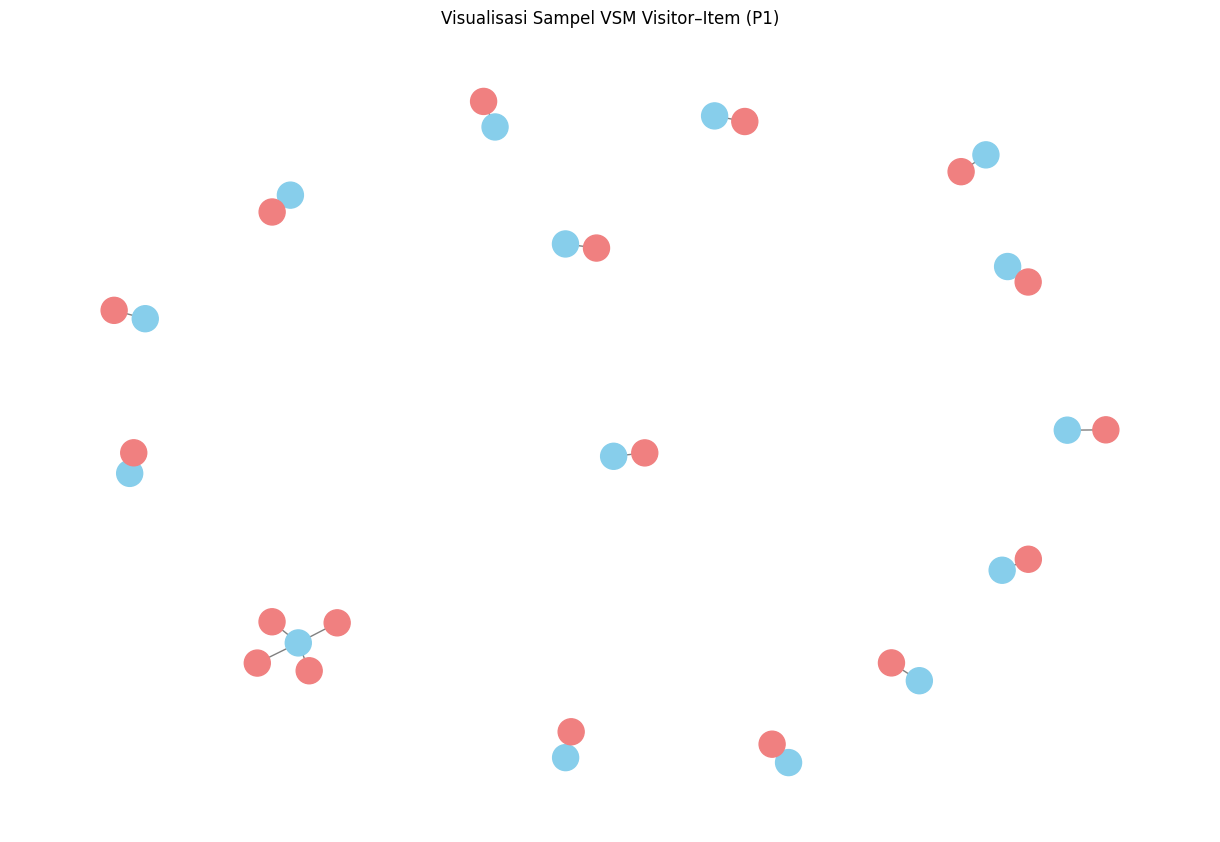

Jumlah node: 33
Jumlah edge: 18


In [87]:
import networkx as nx
import matplotlib.pyplot as plt

# Mengambil 15 Visitor pertama yang memiliki interaksi
sample_visitor = np.flatnonzero(
    np.diff(vsm_visitor.indptr) > 0
)[:15]

G = nx.Graph()

for v_idx in sample_visitor:
    visitor_node = f"V_{visitor_ids[v_idx]}"
    G.add_node(visitor_node, tipe="Visitor")

    # Mengambil Item yang terhubung dengan Visitor
    item_indices = vsm_visitor[v_idx].indices

    for i_idx in item_indices:
        item_node = f"I_{item_ids[i_idx]}"
        G.add_node(item_node, tipe="Item")
        G.add_edge(visitor_node, item_node)

# Warna berdasarkan jenis node
colors = [
    "skyblue" if G.nodes[n]["tipe"] == "Visitor"
    else "lightcoral"
    for n in G.nodes()
]

plt.figure(figsize=(12, 8))

nx.draw(
    G,
    pos=nx.spring_layout(G, seed=42),
    node_color=colors,
    node_size=350,
    with_labels=False,
    edge_color="gray"
)

plt.title("Visualisasi Sampel VSM Visitor–Item (P1)")
plt.show()

print("Jumlah node:", G.number_of_nodes())
print("Jumlah edge:", G.number_of_edges())

**Hasil Visualisasi VSM Visitor Menggunakan NetworkX**

Berdasarkan visualisasi sampel VSM Visitor pada periode P1 (1–14 Juli 2015), diperoleh graf dengan **33 node dan 18 edge**. Node terdiri dari 15 Visitor dan 18 Item unik.

Node berwarna biru muda merepresentasikan Visitor, sedangkan node berwarna merah muda merepresentasikan Item. Edge menunjukkan adanya interaksi antara Visitor dan Item.

Sebagian besar Visitor dalam sampel hanya terhubung dengan satu Item, sedangkan beberapa Visitor memiliki interaksi dengan lebih dari satu Item. Graf membentuk beberapa kelompok terpisah karena tidak terdapat Item yang digunakan bersama oleh Visitor dalam sampel tersebut.

Visualisasi ini hanya menggambarkan sebagian kecil dari keseluruhan VSM Visitor karena jumlah data P1 terlalu besar untuk ditampilkan seluruhnya.

#### 2.1.5 Membuat Vector Space Model (VSM) Item

VSM Item digunakan untuk merepresentasikan produk berdasarkan Visitor yang pernah berinteraksi dengannya. Setiap baris mewakili satu Item, sedangkan setiap kolom mewakili satu Visitor.

Nilai matriks menggunakan representasi biner, yaitu 1 jika Visitor pernah berinteraksi dengan Item tersebut dan 0 jika tidak ada interaksi yang tercatat.

VSM Item dibuat dengan melakukan transpose terhadap VSM Visitor, sehingga posisi baris dan kolom saling bertukar.

In [88]:
# Membuat VSM Item dari transpose VSM Visitor
vsm_item = vsm_visitor.transpose().tocsr()

print("Shape VSM Item:", vsm_item.shape)
print("Jumlah interaksi unik:", vsm_item.nnz)

Shape VSM Item: (83507, 171802)
Jumlah interaksi unik: 247127


**Karakteristik VSM Item**

VSM Item dibuat untuk merepresentasikan produk berdasarkan pengguna yang pernah berinteraksi dengannya pada periode P1 (1–14 Juli 2015). Setiap baris mewakili satu Item dan setiap kolom mewakili satu Visitor.

Nilai matriks menggunakan representasi biner, yaitu 1 jika Visitor pernah berinteraksi dengan Item dan 0 jika tidak ada interaksi yang tercatat.

VSM Item dibuat dengan melakukan *transpose* terhadap VSM Visitor. Matriks disimpan dalam format *sparse CSR* karena sebagian besar elemen bernilai 0.

**Dimensi dan Bentuk VSM Item**

Hasil pembentukan VSM Item menghasilkan matriks berukuran **83.507 × 171.802**, dengan 83.507 baris Item dan 171.802 kolom Visitor.

Jumlah pasangan interaksi unik adalah **247.127**, sama seperti VSM Visitor. Hal ini karena proses *transpose* hanya menukar posisi baris dan kolom tanpa mengubah jumlah interaksi.

Perbedaan utama kedua VSM terletak pada objek yang direpresentasikan. VSM Visitor menggambarkan pengguna berdasarkan produk yang diakses, sedangkan VSM Item menggambarkan produk berdasarkan pengguna yang mengaksesnya.

**Visualisasi VSM Item Menggunakan NetworkX**

Visualisasi dilakukan dengan mengambil sampel 15 Item beserta Visitor yang pernah berinteraksi dengannya. Sampel digunakan karena ukuran VSM Item terlalu besar untuk divisualisasikan seluruhnya.

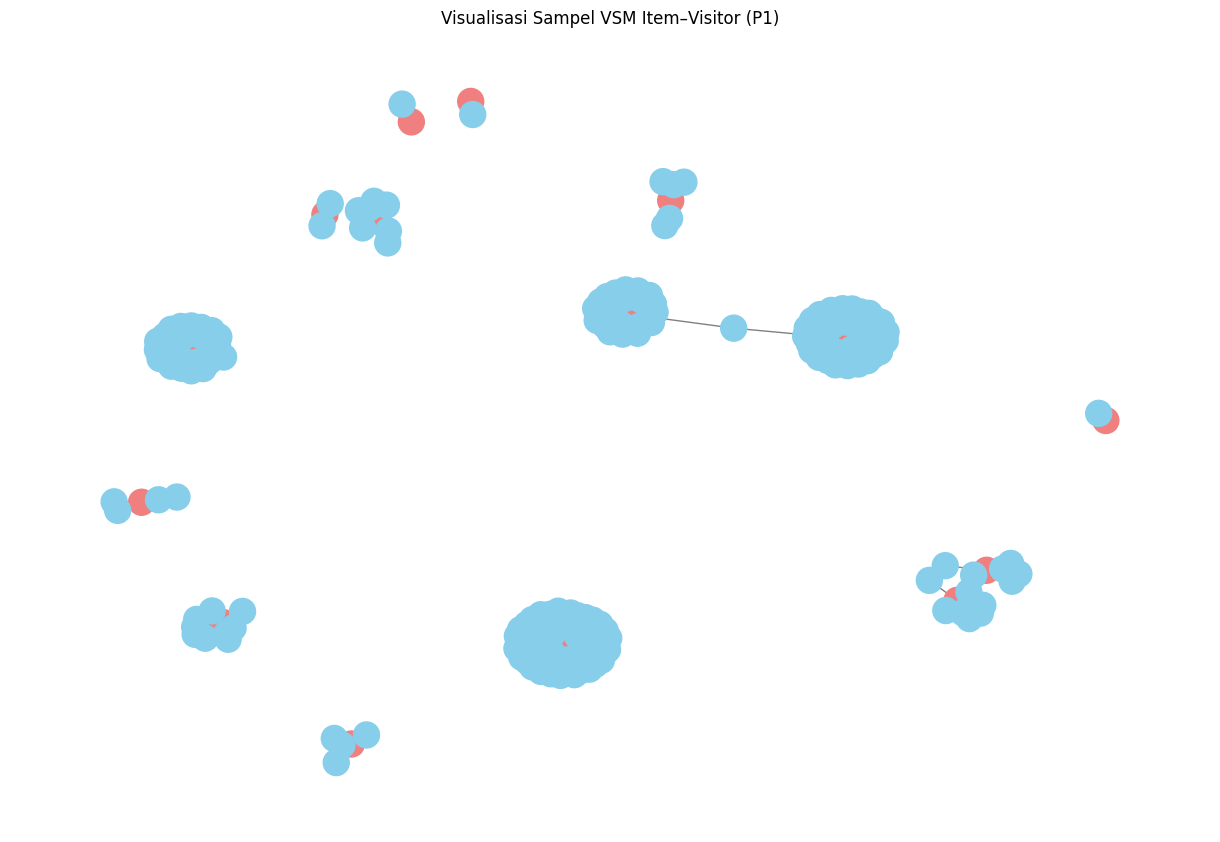

Jumlah node: 221
Jumlah edge: 207


In [89]:
# Mengambil 15 Item pertama yang memiliki interaksi
sample_item = np.flatnonzero(
    np.diff(vsm_item.indptr) > 0
)[:15]

G_item = nx.Graph()

for i_idx in sample_item:
    item_node = f"I_{item_ids[i_idx]}"
    G_item.add_node(item_node, tipe="Item")

    # Mengambil Visitor yang pernah berinteraksi dengan Item
    visitor_indices = vsm_item[i_idx].indices

    for v_idx in visitor_indices:
        visitor_node = f"V_{visitor_ids[v_idx]}"
        G_item.add_node(visitor_node, tipe="Visitor")
        G_item.add_edge(item_node, visitor_node)

# Menentukan warna berdasarkan jenis node
colors_item = [
    "lightcoral" if G_item.nodes[n]["tipe"] == "Item"
    else "skyblue"
    for n in G_item.nodes()
]

plt.figure(figsize=(12, 8))

nx.draw(
    G_item,
    pos=nx.spring_layout(G_item, seed=42),
    node_color=colors_item,
    node_size=350,
    with_labels=False,
    edge_color="gray"
)

plt.title("Visualisasi Sampel VSM Item–Visitor (P1)")
plt.show()

print("Jumlah node:", G_item.number_of_nodes())
print("Jumlah edge:", G_item.number_of_edges())

**Hasil Visualisasi VSM Item Menggunakan NetworkX**

Berdasarkan visualisasi sampel VSM Item pada periode P1 (1–14 Juli 2015), diperoleh graf dengan **221 node dan 207 edge**. Graf terdiri dari **15 Item dan 206 Visitor unik** yang pernah berinteraksi dengan Item tersebut.

Node berwarna merah muda merepresentasikan Item, sedangkan node berwarna biru muda merepresentasikan Visitor. Edge menunjukkan adanya interaksi antara Visitor dan Item.

Visualisasi menunjukkan bahwa beberapa Item memiliki hubungan dengan banyak Visitor sehingga membentuk kelompok node yang padat. Selain itu, terdapat Visitor yang terhubung dengan lebih dari satu Item, sehingga beberapa kelompok dapat saling terhubung.

Visualisasi ini hanya menggunakan sampel 15 Item karena keseluruhan VSM Item terlalu besar untuk ditampilkan dalam satu graf.

#### 2.1.6 Perbandingan Efisiensi dan Efektivitas VSM Visitor dan VSM Item

Perbandingan dilakukan untuk mengetahui perbedaan kedua VSM dari segi ukuran matriks, penggunaan memori, dan kegunaannya dalam analisis. Penggunaan memori dihitung berdasarkan array penyusun sparse matrix CSR.

In [90]:
# Menghitung penggunaan memori sparse matrix CSR
def ukuran_memori_mb(matrix):
    total_bytes = (
        matrix.data.nbytes
        + matrix.indices.nbytes
        + matrix.indptr.nbytes
    )
    return total_bytes / (1024 ** 2)

memori_visitor = ukuran_memori_mb(vsm_visitor)
memori_item = ukuran_memori_mb(vsm_item)

print("VSM Visitor")
print("Shape:", vsm_visitor.shape)
print("Memori:", round(memori_visitor, 2), "MB")

print("\nVSM Item")
print("Shape:", vsm_item.shape)
print("Memori:", round(memori_item, 2), "MB")

VSM Visitor
Shape: (171802, 83507)
Memori: 2.54 MB

VSM Item
Shape: (83507, 171802)
Memori: 2.2 MB


**Perbandingan Efisiensi dan Efektivitas VSM**

Berdasarkan hasil pengukuran, VSM Visitor memiliki ukuran **171.802 × 83.507** dengan penggunaan memori sekitar **2,54 MB**. Sementara itu, VSM Item memiliki ukuran **83.507 × 171.802** dengan penggunaan memori sekitar **2,20 MB**.

Dari segi efisiensi memori, VSM Item lebih hemat sekitar **0,34 MB** dibandingkan VSM Visitor. Perbedaan ini terjadi karena format CSR menyimpan informasi indeks baris, sedangkan jumlah baris pada kedua matriks berbeda.

Dari segi efektivitas, VSM Visitor lebih sesuai untuk mencari kemiripan antar-pengguna berdasarkan produk yang pernah mereka akses. Sementara itu, VSM Item lebih sesuai untuk mencari kemiripan antar-produk berdasarkan pengguna yang pernah berinteraksi dengannya.

Pada pengerjaan ini, VSM Visitor digunakan untuk sistem rekomendasi berbasis pengguna (*user-based collaborative filtering*) dengan metode K-Nearest Neighbors (KNN).

**Kesimpulan:** VSM Item lebih efisien dari segi penggunaan memori CSR berdasarkan pengukuran yang dilakukan. Namun, VSM Visitor lebih sesuai dengan tujuan sistem rekomendasi berbasis pengguna pada tugas ini. Perbandingan efektivitas tersebut didasarkan pada kesesuaian metode, bukan hasil pengujian akurasi kedua pendekatan.

#### 2.1.7 Menghitung Similarity Antar-Visitor

Kemiripan antar-Visitor dihitung menggunakan Cosine Similarity berdasarkan VSM Visitor pada periode P1. Metode ini membandingkan pola interaksi produk antar-pengguna.

Nilai similarity berada pada rentang 0 sampai 1 karena VSM menggunakan nilai biner. Semakin mendekati 1, semakin mirip pola interaksi kedua Visitor.

Pada analisis ini digunakan Visitor 1150086 sebagai contoh, kemudian dicari lima Visitor dengan nilai similarity tertinggi.

In [91]:
# Memeriksa apakah Visitor target ada dalam P1 baru
target_visitor = 1150086

print("Visitor target:", target_visitor)
print("Ada dalam P1 baru:", target_visitor in visitor_ids)

Visitor target: 1150086
Ada dalam P1 baru: True


In [92]:
from sklearn.metrics.pairwise import cosine_similarity

# Visitor yang akan dibandingkan
target_visitor = 1150086

# Mencari indeks Visitor pada VSM
target_idx = visitor_ids.get_loc(target_visitor)

# Menghitung similarity terhadap seluruh Visitor
similarities = cosine_similarity(
    vsm_visitor[target_idx],
    vsm_visitor
).flatten()

# Mengeluarkan Visitor target dari hasil
similarities[target_idx] = -1

# Mengambil 5 Visitor dengan similarity tertinggi
top5_idx = np.argsort(similarities)[-5:][::-1]

# Menampilkan hasil
top5_similarity = pd.DataFrame({
    "visitorid": visitor_ids[top5_idx],
    "similarity": similarities[top5_idx]
})

display(top5_similarity)

,visitorid,similarity
0,1297062,0.155181
1,371606,0.126358
2,705542,0.123148
3,530559,0.116622
4,836635,0.084013


**Hasil Cosine Similarity Antar-Visitor**

Pada analisis ini digunakan Visitor `1150086` sebagai target untuk mencari lima Visitor dengan nilai Cosine Similarity tertinggi berdasarkan VSM Visitor pada periode P1 (1–14 Juli 2015).

Hasil perhitungan menunjukkan bahwa Visitor `1297062` memiliki similarity tertinggi sebesar **0,155181**, diikuti Visitor `371606` sebesar **0,126358**, Visitor `705542` sebesar **0,123148**, Visitor `530559` sebesar **0,116622**, dan Visitor `836635` sebesar **0,084013**.

Nilai similarity yang relatif rendah menunjukkan bahwa pola interaksi produk antara Visitor target dan lima Visitor terdekat masih memiliki tingkat kesamaan yang terbatas. Hal ini dapat dipengaruhi oleh karakteristik data interaksi yang bersifat sparse, yaitu sebagian besar Visitor hanya berinteraksi dengan sebagian kecil Item.

**Menyimpan Hasil Similarity ke Neo4j**

Lima Visitor dengan nilai Cosine Similarity tertinggi disimpan ke Neo4j menggunakan relationship `SIMILAR_TO`. Setiap relationship memiliki properti `score` yang menunjukkan nilai kemiripan antar-Visitor.

In [93]:
query_save_similarity = """
UNWIND $data AS row

MATCH (v1:Visitor {visitorId: $target})
MATCH (v2:Visitor {visitorId: row.visitorid})

MERGE (v1)-[r:SIMILAR_TO]->(v2)
SET r.score = row.similarity

RETURN count(r) AS jumlah
"""

data_similarity = [
    {
        "visitorid": int(row.visitorid),
        "similarity": float(row.similarity)
    }
    for row in top5_similarity.itertuples(index=False)
]

with driver.session(database="retailrocket") as session:
    result = session.run(
        query_save_similarity,
        target=int(target_visitor),
        data=data_similarity
    ).single()

    print("Jumlah relationship yang diproses:", result["jumlah"])

Jumlah relationship yang diproses: 5


**Menampilkan Hasil Similarity dari Neo4j**

Setelah relationship `SIMILAR_TO` disimpan, dilakukan pemeriksaan menggunakan query Cypher untuk menampilkan lima Visitor yang memiliki kemiripan tertinggi dengan Visitor 1150086 beserta nilai similarity-nya.

In [94]:
query_check_similarity = """
MATCH (v1:Visitor {visitorId: $target})-[r:SIMILAR_TO]->(v2:Visitor)
RETURN v1.visitorId AS visitor_target,
       v2.visitorId AS visitor_mirip,
       r.score AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session(database="retailrocket") as session:
    result = session.run(
        query_check_similarity,
        target=int(target_visitor)
    )

    df_similarity_neo4j = pd.DataFrame(
        [dict(record) for record in result]
    )

display(df_similarity_neo4j)

,visitor_target,visitor_mirip,similarity
0,1150086,1297062,0.155181
1,1150086,371606,0.126358
2,1150086,705542,0.123148
3,1150086,530559,0.116622
4,1150086,836635,0.084013


**Hasil Penyimpanan Similarity di Neo4j**

Berdasarkan hasil pemeriksaan, lima relationship `SIMILAR_TO` dari Visitor `1150086` berhasil disimpan dan ditampilkan kembali melalui query Cypher.

Visitor `1297062` memiliki nilai similarity tertinggi sebesar **0,155181**, sedangkan Visitor `836635` memiliki nilai similarity terendah di antara lima Visitor terpilih, yaitu **0,084013**.

Hasil yang ditampilkan Neo4j sesuai dengan hasil perhitungan Cosine Similarity menggunakan Python. Hal ini menunjukkan bahwa proses penyimpanan relationship dan properti `score` telah berjalan dengan benar.

#### 2.1.8 Perbandingan Graf Sebelum dan Sesudah Similarity

Perbandingan dilakukan menggunakan query Cypher pada Neo4j. Graf sebelum penambahan similarity menampilkan hubungan aktivitas Visitor dengan Item, sedangkan graf sesudahnya juga menampilkan relationship `SIMILAR_TO` antar-Visitor.

**Hasil Perbandingan Graf Sebelum dan Sesudah Similarity**

Pada graf sebelum similarity, Visitor 1150086 ditampilkan bersama Item yang pernah diaksesnya melalui relationship aktivitas, seperti VIEWED, ADDED_TO_CART, dan BOUGHT.

- Graph Sebelum Similarity
![Graph Sebelum](Graf_Sebelum_Similarity.png)

Setelah penambahan similarity, graf menampilkan hubungan tambahan antar-Visitor melalui relationship SIMILAR_TO. Pada visualisasi sesudah similarity, terlihat Visitor 530559 yang terhubung dengan Visitor 1150086.

- Graph Setelah Similarity
![Graph Sebelum](Graf_Sesudah_Similarity.png)

Berdasarkan hasil perhitungan dan penyimpanan similarity di Neo4j, terdapat lima Visitor dengan nilai kemiripan tertinggi terhadap Visitor 1150086, yaitu 1297062, 371606, 705542, 530559, dan 836635. Namun, tidak seluruh hubungan tersebut terlihat pada screenshot karena visualisasi menggunakan pembatasan hasil query.

Perbedaan kedua graf menunjukkan bahwa graf tidak hanya menyimpan interaksi antara pengguna dan produk, tetapi juga dapat merepresentasikan kemiripan antar-pengguna berdasarkan pola interaksi mereka.

Perbandingan dilakukan dengan membedakan relationship yang ditampilkan melalui query Cypher, tanpa menghapus data yang sudah tersimpan di Neo4j.

### 2.2 Analytics

#### 2.2.1 Rekomendasi Item Menggunakan User-Based KNN

Sistem rekomendasi dibuat menggunakan pendekatan User-Based Collaborative Filtering dengan metode K-Nearest Neighbors (KNN) dan nilai k = 5.

Data P1 digunakan untuk mencari kemiripan antar-Visitor dan menghasilkan rekomendasi Item, sedangkan data P2 digunakan untuk mengevaluasi hasil rekomendasi.

Pemilihan Visitor dilakukan secara acak menggunakan random seed 42 agar hasilnya dapat direproduksi.

In [95]:
# Memilih Visitor secara acak dengan hasil yang dapat direproduksi
# Syarat: minimal 5 Item unik di P1 dan memiliki Item baru di P2

item_p1_per_visitor = df_p1.groupby("visitorid")["itemid"].agg(set)
item_p2_per_visitor = df_p2.groupby("visitorid")["itemid"].agg(set)

eligible_visitors = [
    visitor
    for visitor, items_p1 in item_p1_per_visitor.items()
    if len(items_p1) >= 5
    and visitor in item_p2_per_visitor.index
    and len(item_p2_per_visitor[visitor] - items_p1) > 0
]

print("Jumlah Visitor yang memenuhi syarat:", len(eligible_visitors))

Jumlah Visitor yang memenuhi syarat: 490


In [96]:
import random

# Memilih satu Visitor secara acak
random.seed(42)
target_visitor_knn = random.choice(eligible_visitors)

print("Visitor terpilih:", target_visitor_knn)

# Melihat jumlah Item yang diakses Visitor pada P1 dan P2
items_train = item_p1_per_visitor[target_visitor_knn]
items_test = item_p2_per_visitor[target_visitor_knn]

print("Jumlah Item unik P1:", len(items_train))
print("Jumlah Item unik P2:", len(items_test))
print("Jumlah Item baru di P2:", len(items_test - items_train))

Visitor terpilih: 957260
Jumlah Item unik P1: 5
Jumlah Item unik P2: 1
Jumlah Item baru di P2: 1


**Mencari Lima Tetangga Terdekat**

Lima Visitor terdekat dicari menggunakan Cosine Similarity pada VSM Visitor periode P1. Visitor target tidak dimasukkan sebagai tetangganya sendiri. Hasil similarity digunakan untuk menentukan lima tetangga terdekat (k = 5).

In [97]:
# Mengambil indeks Visitor target
target_idx_knn = visitor_ids.get_loc(target_visitor_knn)

# Menghitung Cosine Similarity terhadap seluruh Visitor
similarities_knn = cosine_similarity(
    vsm_visitor[target_idx_knn],
    vsm_visitor
).flatten()

# Mengeluarkan Visitor target
similarities_knn[target_idx_knn] = -1

# Mengambil 5 tetangga dengan similarity positif tertinggi
top5_knn_idx = np.argsort(similarities_knn)[::-1]
top5_knn_idx = [
    idx for idx in top5_knn_idx
    if similarities_knn[idx] > 0
][:5]

# Menampilkan hasil
df_knn = pd.DataFrame({
    "visitorid": visitor_ids[top5_knn_idx],
    "similarity": similarities_knn[top5_knn_idx]
})

display(df_knn)

,visitorid,similarity
0,660752,0.632456
1,1212535,0.577350
2,39211,0.516398
3,844131,0.447214
4,729277,0.447214


In [98]:
# Mengambil Item yang sudah diakses Visitor target pada P1
items_target = set(vsm_visitor[target_idx_knn].indices)

# Mengurutkan Visitor berdasarkan similarity tertinggi
urutan_similarity = np.argsort(similarities_knn)[::-1]

# Memilih maksimal 5 tetangga yang memiliki Item baru
top5_knn_idx = []

for idx in urutan_similarity:
    if similarities_knn[idx] <= 0:
        break

    items_tetangga = set(vsm_visitor[idx].indices)
    item_baru = items_tetangga - items_target

    if len(item_baru) > 0:
        top5_knn_idx.append(idx)

    if len(top5_knn_idx) == 5:
        break

# Menampilkan tetangga terpilih
df_knn = pd.DataFrame({
    "visitorid": visitor_ids[top5_knn_idx],
    "similarity": similarities_knn[top5_knn_idx],
    "jumlah_item_baru": [
        len(set(vsm_visitor[idx].indices) - items_target)
        for idx in top5_knn_idx
    ]
})

display(df_knn)

,visitorid,similarity,jumlah_item_baru
0,1212535,0.577350,10
1,39211,0.516398,1
2,1028473,0.447214,2
3,910946,0.424264,7
4,1325370,0.316228,1


Lima tetangga terdekat dipilih menggunakan Cosine Similarity pada VSM Visitor periode P1. Pemilihan dilakukan berdasarkan nilai similarity positif tertinggi, dengan syarat setiap tetangga memiliki minimal satu Item yang belum pernah diakses oleh Visitor target pada P1. Dengan demikian, tetangga yang terpilih dapat digunakan sebagai sumber kandidat Item rekomendasi.

**Menentukan Tiga Rekomendasi Item**

Rekomendasi dibuat berdasarkan Item yang pernah diakses oleh lima tetangga terdekat, tetapi belum pernah diakses oleh Visitor target pada P1.

Setiap kandidat Item diberi skor berdasarkan jumlah nilai Cosine Similarity dari tetangga yang pernah mengaksesnya. Tiga Item dengan skor tertinggi dipilih sebagai hasil rekomendasi.

In [99]:
from collections import defaultdict

# Item yang sudah diakses Visitor target pada P1
items_target = set(vsm_visitor[target_idx_knn].indices)

# Menghitung skor kandidat rekomendasi
skor_item = defaultdict(float)

for idx in top5_knn_idx:
    similarity = similarities_knn[idx]

    # Item yang pernah diakses tetangga
    items_tetangga = set(vsm_visitor[idx].indices)

    # Hanya Item yang belum diakses target
    kandidat = items_tetangga - items_target

    for item_idx in kandidat:
        skor_item[item_idx] += similarity

# Mengurutkan kandidat berdasarkan skor tertinggi
ranking_item = sorted(
    skor_item.items(),
    key=lambda x: (-x[1], int(item_ids[x[0]]))
)

# Mengambil 3 rekomendasi teratas
top3_rekomendasi = ranking_item[:3]

df_rekomendasi = pd.DataFrame([
    {
        "itemid": int(item_ids[idx]),
        "skor": round(float(skor), 6)
    }
    for idx, skor in top3_rekomendasi
])

print("Jumlah kandidat Item:", len(ranking_item))
display(df_rekomendasi)

Jumlah kandidat Item: 20


,itemid,skor
0,268889,1.001614
1,68128,0.577350
2,69504,0.577350


### 2.2.2 Evaluasi Rekomendasi Menggunakan Hit@5 dan NDCG@5

Evaluasi dilakukan dengan membandingkan lima Item rekomendasi teratas berdasarkan data P1 terhadap Item baru yang diakses Visitor target pada periode P2.

Metrik Hit@5 digunakan untuk mengetahui apakah terdapat minimal satu Item relevan dalam lima rekomendasi teratas, sedangkan NDCG@5 digunakan untuk mengukur kualitas peringkat rekomendasi berdasarkan posisi Item relevan.

In [100]:
# Mengambil 5 rekomendasi Item teratas
top5_rekomendasi = [
    int(item_ids[idx])
    for idx, skor in ranking_item[:5]
]

# Mengambil Item baru yang diakses Visitor target pada P2
item_relevan = set(items_test) - set(items_train)

print("Visitor target:", target_visitor_knn)
print("Top-5 rekomendasi:", top5_rekomendasi)
print("Item relevan di P2:", sorted(item_relevan))

Visitor target: 957260
Top-5 rekomendasi: [268889, 68128, 69504, 140861, 292444]
Item relevan di P2: [392423]


In [101]:
# Menghitung Hit@5
hit_at_5 = int(any(
    item in item_relevan
    for item in top5_rekomendasi
))

# Menghitung DCG@5
dcg = sum(
    1 / np.log2(i + 2)
    for i, item in enumerate(top5_rekomendasi)
    if item in item_relevan
)

# Menghitung IDCG@5
jumlah_relevan = min(len(item_relevan), 5)

idcg = sum(
    1 / np.log2(i + 2)
    for i in range(jumlah_relevan)
)

# Menghitung NDCG@5
ndcg_at_5 = dcg / idcg if idcg > 0 else 0

print("Hit@5:", hit_at_5)
print("NDCG@5:", round(ndcg_at_5, 6))

Hit@5: 0
NDCG@5: 0.0


**Hasil Evaluasi Hit@5 dan NDCG@5**

Evaluasi dilakukan terhadap Visitor `957260` menggunakan lima rekomendasi Item teratas dari data P1 (1–14 Juli 2015) dan Item relevan dari data P2 (15–21 Juli 2015).

Lima Item yang direkomendasikan adalah `268889`, `68128`, `69504`, `140861`, dan `292444`, sedangkan Item baru yang diakses Visitor pada P2 adalah `392423`.

Hasil evaluasi menunjukkan nilai **Hit@5 = 0** dan **NDCG@5 = 0.0**. Hal ini terjadi karena tidak ada Item relevan yang muncul dalam lima rekomendasi teratas.

Dengan demikian, sistem rekomendasi belum berhasil memprediksi Item baru yang diakses Visitor tersebut pada periode P2. Namun, hasil ini hanya menggambarkan evaluasi terhadap satu Visitor dan belum mewakili kinerja sistem secara keseluruhan.